# Preprocessing and Feature Extraction for Document

### Authors - Shivendra Raghav (1001123853), Amirhosein Morteza (1002187551)
### CSE 5388-002

#### This files preprocesses the data and does feature extraction.

### Import the required libraries

In [94]:
import re
import nltk
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import gensim.downloader as api
from imblearn.under_sampling import RandomUnderSampler
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [95]:
nltk.download("punkt")

glove_model = api.load("glove-wiki-gigaword-300")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/shivendraraghav/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/shivendraraghav/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Load the dataset

In [96]:
df = pd.read_csv("../synthetic_dataset/document_classified_data.csv")

df.head()

,filename,text,processed_text,sensitive,ner_metadata
0,dasovich-j_sent_917.txt,Message-ID: <16197052.1075843205891.JavaMail.e...,Message-ID: <16197052.1075843205891.JavaMail.e...,0,[]
1,technology_prompt_storage_16_1_not_processed.txt,Scaleway Object Storage Documentation\n\nIntro...,Scaleway Object Storage Documentation\n\nIntro...,0,[]
2,taylor-m_sent_628.txt,Message-ID: <27392847.1075860063119.JavaMail.e...,Message-ID: <27392847.1075860063119.JavaMail.e...,0,[]
3,mann-k_sent_82.txt,Message-ID: <21848911.1075845920460.JavaMail.e...,Message-ID: <21848911.1075845920460.JavaMail.e...,0,[]
4,business_prompt_14_1_1.txt,## Standard Operating Procedure (SOP) for Auto...,## Standard Operating Procedure (SOP) for Auto...,0,[]


In [97]:
# Check for missing values
df.isnull().sum()

filename          0
text              0
processed_text    0
sensitive         0
ner_metadata      0
dtype: int64

### Data Cleaning and Preprocessing

In [98]:
def preprocess_text(text):
    text = re.sub(r'Message-ID:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Date:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'From:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'To:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Subject:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Cc:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Mime-Version:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Content-Type:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Content-Transfer-Encoding:.*\n', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Bcc:.*\n', '', text, flags=re.IGNORECASE)

    # Convert to lowercase
    text = text.lower()
    
    return text

In [99]:

df['token_processed_text'] = df['processed_text'].apply(preprocess_text)

# Drop duplicates and empty documents
df.drop_duplicates(subset="token_processed_text", inplace=True)
df.dropna(subset=["token_processed_text"], inplace=True)

df.head()

,filename,text,processed_text,sensitive,ner_metadata,token_processed_text
0,dasovich-j_sent_917.txt,Message-ID: <16197052.1075843205891.JavaMail.e...,Message-ID: <16197052.1075843205891.JavaMail.e...,0,[],x-x-x-x-bx-folder: \jeff_dasovich_dec2000\note...
1,technology_prompt_storage_16_1_not_processed.txt,Scaleway Object Storage Documentation\n\nIntro...,Scaleway Object Storage Documentation\n\nIntro...,0,[],scaleway object storage documentation\n\nintro...
2,taylor-m_sent_628.txt,Message-ID: <27392847.1075860063119.JavaMail.e...,Message-ID: <27392847.1075860063119.JavaMail.e...,0,[],x-x-x-x-bx-folder: \mark_taylor _dec_2000\note...
3,mann-k_sent_82.txt,Message-ID: <21848911.1075845920460.JavaMail.e...,Message-ID: <21848911.1075845920460.JavaMail.e...,0,[],x-x-x-x-bx-folder: \kay_mann_june2001_3\notes ...
4,business_prompt_14_1_1.txt,## Standard Operating Procedure (SOP) for Auto...,## Standard Operating Procedure (SOP) for Auto...,0,[],## standard operating procedure (sop) for auto...


### Data Exploration

/var/folders/rz/4djzw0r155g8_kdwpx3gm7y40000gn/T/ipykernel_2315/2708613916.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sensitive", data=df, palette=["#175676", "#d62839"])


Text(0.5, 0, 'Sensitive')

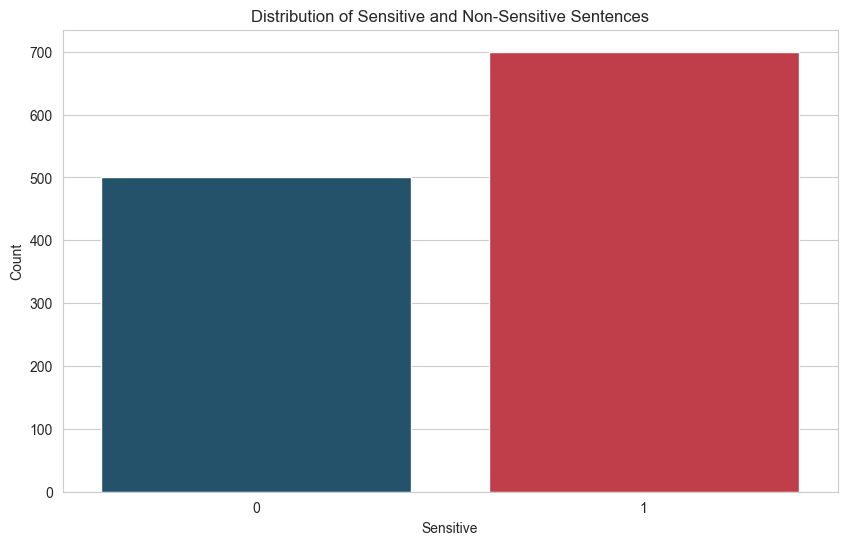

In [100]:
# Distribution of Sensitive and Non-Sensitive Sentences
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
sns.countplot(x="sensitive", data=df, palette=["#175676", "#d62839"])
plt.title("Distribution of Sensitive and Non-Sensitive Sentences")
plt.ylabel("Count")
plt.xlabel("Sensitive")

### GloVe Embeddings and Balancing the dataset

In [101]:
text_tokenizer = Tokenizer()
text_tokenizer.fit_on_texts(df["token_processed_text"])

# Save the tokenizer
text_tokenizer_path = "output/doc_text_tokenizer.pickle"
with open(text_tokenizer_path, "wb") as handle:
    pickle.dump(text_tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [102]:
# Word Index
word_index = text_tokenizer.word_index

# Create a weight matrix for words in training docs
def create_embedding_matrix(word_index, embedding_model):
    embedding_matrix = np.zeros((len(word_index) + 1, embedding_model.vector_size))
    for word, i in word_index.items():
        if word in embedding_model.key_to_index:
            embedding_matrix[i] = embedding_model[word]
    return embedding_matrix

embedding_matrix = create_embedding_matrix(word_index, glove_model)

# Save the embedding matrix
glove_embeddings_path = "output/doc_glove_embeddings.npz"
np.savez_compressed(glove_embeddings_path, embedding_matrix=embedding_matrix)


In [103]:
# Balance the dataset
# smote = SMOTE(random_state=42)
undersampler = RandomUnderSampler(random_state=42)

X = text_tokenizer.texts_to_sequences(df["token_processed_text"])

max_length = 100
X = pad_sequences(X, maxlen=max_length, padding="post")

# X_resampled, y_resampled = smote.fit_resample(X, df["sensitive"])
X_resampled, y_resampled = undersampler.fit_resample(X, df["sensitive"])

# Save the resampled data
df_resampled = pd.DataFrame(columns=["token_processed_text", "sensitive"])
df_resampled["sensitive"] = y_resampled
df_resampled["text"] = text_tokenizer.sequences_to_texts(X_resampled)

df_resampled.drop(columns=["token_processed_text"], inplace=True)

/var/folders/rz/4djzw0r155g8_kdwpx3gm7y40000gn/T/ipykernel_2315/3206030609.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sensitive", data=df_resampled, palette=["#175676", "#d62839"])


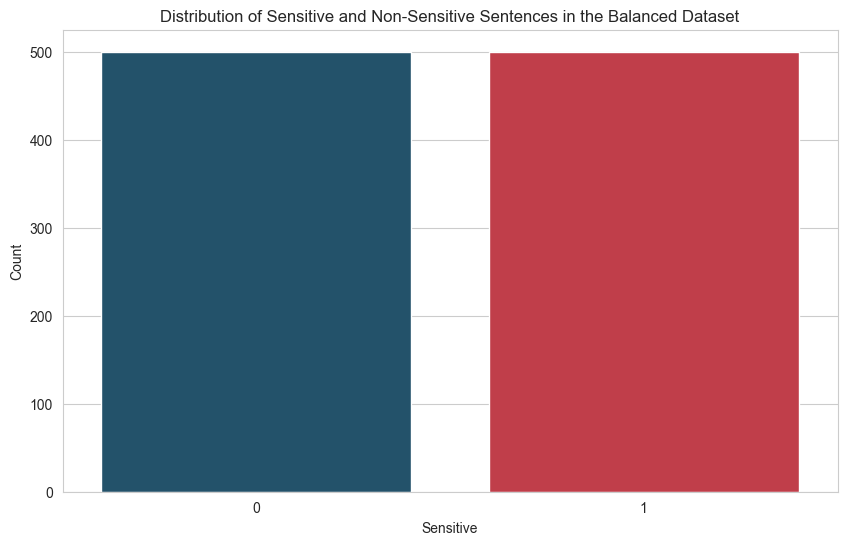

In [104]:
# Distribution of Sensitive and Non-Sensitive Sentences in the Balanced Dataset
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
sns.countplot(x="sensitive", data=df_resampled, palette=["#175676", "#d62839"])
plt.title("Distribution of Sensitive and Non-Sensitive Sentences in the Balanced Dataset")
plt.ylabel("Count")
plt.xlabel("Sensitive")
plt.show()

### Save the data

In [105]:
# Save the resampled data
df_resampled.to_csv("../synthetic_dataset/document_classified_data_resampled.csv", index=False)